In [1]:
import pathlib

from matplotlib import pyplot as plt

import el_hd_plasticity.connectomics as cn
from el_hd_plasticity.connectomics import connectivity, datasets, plotting

plt.rcParams['pdf.fonttype'] = 42

%load_ext autoreload
%autoreload 2
%matplotlib inline

figfolder = pathlib.Path('/media/mplitt/SSD_storage/fig_scratch/EL_connectomics')
figfolder.mkdir(parents=True, exist_ok=True)

## Datasets

The male CNS (MCNS) is read from neuPrint; FAFB and BANC (flywire) from Codex (the API token is read from the `CODEX_API_TOKEN` environment
variable; the tables are downloaded once and cached). Codex's `connections_princeton` only contains connections of at least 5 synapses.

In [2]:
other_datasets = {'MCNS': datasets.NeuprintDataset('MCNS', 'male-cns:v0.9')}
if cn.params.CODEX_TOKEN:
    codex = datasets.CodexClient()
    for name, dataset in (('FAFB', 'fafb'), ('BANC', 'banc')):
        other_datasets[name] = datasets.load_codex(name, dataset, client=codex)
else:
    print('CODEX_API_TOKEN is not set: FAFB and BANC are skipped')

## Connectivity between EL, EPG and ER2/4d

In [3]:
type_tables, graphs = {}, {}
for name, dataset in other_datasets.items():
    type_tables[name], n_neurons = connectivity.dataset_type_connectivity(dataset)
    graphs[name] = connectivity.connectivity_graph(type_tables[name], n_neurons)
    print(name)
    display(type_tables[name])

  0%|          | 0/1 [00:00<?, ?it/s]

0it [00:00, ?it/s]

  0%|          | 0/14 [00:00<?, ?it/s]

  0%|          | 0/14 [00:00<?, ?it/s]

MCNS


,type_pre,type_post,weight,relative_weight,pcnt_output,nrn_weight
0,EL,EPG,3464,0.018677,0.453878,75.304348
1,EPG,EL,8666,0.124565,0.637769,481.444444
2,EL,ER2/4d,6671,0.056034,0.874083,99.567164
3,EPG,ER2/4d,5397,0.045333,0.397189,80.552239
4,ER2/4d,EL,10770,0.154808,0.297975,598.333333
5,ER2/4d,EPG,40676,0.219319,1.125387,884.260870


FAFB


,type_pre,type_post,weight,relative_weight,pcnt_output,nrn_weight
0,EL,EPG,1344,0.021677,0.099342,28.595745
1,EPG,EL,9230,0.178306,0.266432,542.941176
2,EL,ER2/4d,3084,0.136726,0.227955,128.500000
3,EPG,ER2/4d,83,0.003680,0.002396,3.458333
4,ER2/4d,EL,2765,0.053414,0.104450,162.647059
5,ER2/4d,EPG,3070,0.049515,0.115972,65.319149


BANC


,type_pre,type_post,weight,relative_weight,pcnt_output,nrn_weight
0,EL,EPG,31,0.001157,0.252033,0.688889
1,EPG,EL,1999,0.196655,0.137767,111.055556
2,EL,ER2/4d,33,0.001340,0.268293,0.452055
3,EPG,ER2/4d,237,0.009622,0.016334,3.246575
4,ER2/4d,EL,1294,0.127300,0.039063,71.888889
5,ER2/4d,EPG,6740,0.251483,0.203466,149.777778


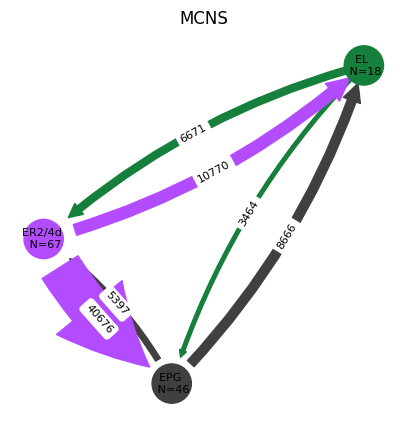

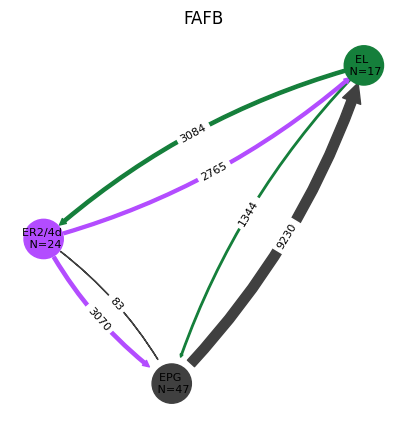

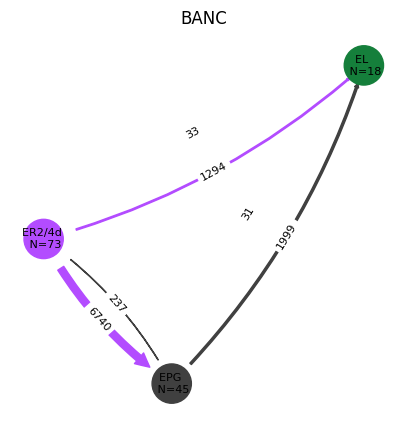

In [4]:
colors = {'EL': plt.cm.Greens(.8), 'EPG': plt.cm.Greys(.8), 'ER2/4d': plt.cm.cool(.7)}
pos = {'ER2/4d': [.2, .4], 'EL': [.7, .7], 'EPG': [.4, .15]}

for name, graph in graphs.items():
    fig, ax = plotting.plot_connectivity_graph(graph, colors, pos, edge_attr='weight')
    ax.set_title(name)
    # fig.savefig(figfolder / f'connectivity_graph_{name}.pdf')